In [ ]:
import time
import diffrax
import equinox as eqx  # https://github.com/patrick-kidger/equinox
import jax
import jax.nn as jnn
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import optax  # https://github.com/deepmind/optax
import pandas as pd

from __future__ import annotations
from typing import Literal
Array = "jax.Array"

from ude import (
    NDE, ODE, ODEcore, UDE, OdeProblem,
    train_model,
    simulate_reference, prepare_data,
    plot_comparison, plot_learned_term,
)

ModuleNotFoundError: No module named 'ude'

: 

ODE in jax

In [ ]:
class ODE_Lodka_Volterra(eqx.Module):
    """
    Part of the Lodka-Volterra model, the rest is learned by the NN"
    State vector (2 components)
    ---------------------------
    x (Pray)
    y (Preditor)

    Parameter vector (2 components)
    ---------------------------------
    r1, r1, c1, c2

    Parameters
    ----------
    weights : jax.Array, shape (4,)

    Examples
    --------
    >>> ode = ODE(weights=Lodka_Volterra)
    >>> ode(t=0.0, y=y0_Lodka_Volterra, args=None)   # returns shape (7,)
    """

    weights: Array

    def __call__(self, t: float, variables: Array, args) -> Array:
        x,y = variables
        r1,r2,c1,c2 = self.weights

        dxdt   = r1 * x - y*x*c1
        dydt   = - r2 * y + y*x*c2

        return jnp.array([dxdt, dydt])


In [ ]:
ode_problem = OdeProblem(
    ODE_Lodka_Volterra(weights=[0.3,0.3,0.5,0.5]),
    full_state=False,
)
t_steps= jnp.linspace(0,100,200)
start_condition= jnp.array([2.0,1.0])
ode_solution = ode_problem(t_steps,start_condition)

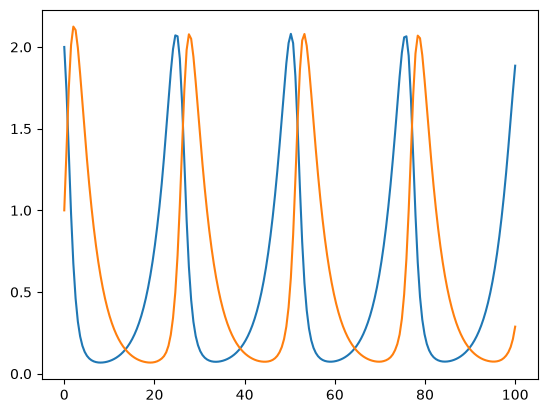

In [ ]:
plt.plot(t_steps,ode_solution)

The ODE works now the UDE
1. NDE
2. ODE to combine
3. Data + Training

In [2]:
class ANN(eqx.Module):
    out_scale: jax.Array 
    mlp: eqx.nn.MLP

    def __init__(self, data_size, width_size, depth, *, key, **kwargs):
        
        super().__init__(**kwargs)
        self.out_scale = jnp.array(1.0)
        self.mlp = eqx.nn.MLP(
            in_size=data_size,
            out_size=data_size,
            width_size=width_size,
            depth=depth,
            activation=jnn.softplus,
            final_activation=jax.nn.tanh,
            key=key,
        )

    def __call__(self, t, y,):
        # Best practice is often to use `learnt_scalar * tanh(MLP(...))` for the
        # vector field.
        return self.out_scale * self.mlp(y)

NameError: name 'eqx' is not defined

In [ ]:
class NDE(eqx.Module):
    """
    A fully data-driven model: a multi-layer perceptron (MLP) approximates
    the full vector field.

    The MLP maps the current state ``y ∈ ℝ^in_size`` to a time-derivative
    vector ``dy/dt ∈ ℝ^out_size``.  When used inside a UDE, ``out_size``
    should match the state dimension of the mechanistic ODE so that the
    outputs can be added element-wise.

    Parameters
    ----------
    in_size : int
        Dimension of the state vector (input to the MLP).
    out_size : int
        Dimension of the output (should equal state dimension for a UDE).
    width_size : int
        Number of neurons per hidden layer.
    depth : int
        Number of hidden layers (not counting input/output layers).
    key : jax.Array
        PRNG key for weight initialisation.

    Examples
    --------
    >>> nde = NDE(in_size=7, out_size=7, width_size=32, depth=2, key=jax.random.PRNGKey(0))
    >>> nde(t=0.0, y=jnp.ones(7), args=None)   # returns shape (7,)
    """

    out_scale: Array
    mlp: eqx.nn.MLP

    def __init__(
        self,
        in_size: int,
        out_size: int,
        width_size: int,
        depth: int,
        *,
        key: Array,
    ) -> None:
        # Learnable global output scale (initialised at 1)
        self.out_scale = jnp.array(1.0)
        self.mlp = eqx.nn.MLP(
            in_size=in_size,
            out_size=out_size,
            width_size=width_size,
            depth=depth,
            activation=jax.nn.swish,       # smooth & good for ODEs
            final_activation=jax.nn.swish,  # keep final layer non-linear
            key=key,
        )

    def __call__(self, t: float, y: Array, args) -> Array:
        """Evaluate the neural vector field at state ``y``."""
        return self.out_scale * self.mlp(y)

In [1]:
# ===========================================================================
# UDE: Universal Differential Equation (hybrid)
# ===========================================================================

class UDE(eqx.Module):
    """
    Universal Differential Equation: mechanistic ODE + neural network.

    The UDE combines a mechanistic ODE skeleton (``ode``) with a neural
    network (``nde``) to approximate unknown or intractable terms.  The
    combination is:

        UDE(t, y) = combine(ODE(t, y),  λ · constraint(ODE(t, y)) · NDE(t, y))

    where ``combine`` is one of:  add, mul, pow.

    This flexible formulation allows:
    - **Additive correction**: ``operator="add"`` (most common) — the NN adds
      a correction term on top of the mechanistic baseline.
    - **Multiplicative scaling**: ``operator="mul"`` — the NN scales the
      mechanistic output (useful for modelling fold-changes).
    - **Power-law**: ``operator="pow"`` — less common, used for allometric
      relationships.

    The ``constraint`` parameter enforces that the NN correction is
    biologically plausible by gating it through a function of the ODE output:
    - ``"none"``  — no constraint (gate = 1)
    - ``"x"``     — gate = ODE output itself (zeros correction where ODE = 0)
    - ``"tanh"``  — gate = tanh(ODE output), bounded in (-1, 1)

    Parameters
    ----------
    ode : eqx.Module
        Mechanistic right-hand side (e.g. ``ODEcore``).
    nde : eqx.Module
        Neural network right-hand side (e.g. ``NDE``).
    operator : {"add", "mul", "pow"}, default "add"
        How to combine ODE and NDE outputs.
    lambda_ : float, default 2.0
        Scaling factor for the neural network contribution.
    constraint : {"none", "x", "tanh"}, default "none"
        Constraint applied to ODE output before multiplying with NDE.

    """

    ode: eqx.Module
    nde: eqx.Module
    operator: str
    lambda_: float
    constraint: str

    def __init__(
        self,
        ode: eqx.Module,
        nde: eqx.Module,
        operator: OperatorMode = "mul",
        lambda_: float = 2.0,
        constraint: ConstraintMode = "none",
    ) -> None:
        if operator not in ("add", "mul", "pow"):
            raise ValueError(f"operator must be 'add', 'mul', or 'pow', got {operator!r}")
        if constraint not in ("none", "x", "tanh"):
            raise ValueError(f"constraint must be 'none', 'x', or 'tanh', got {constraint!r}")
        self.ode = ode
        self.nde = nde
        self.operator = operator
        self.lambda_ = lambda_
        self.constraint = constraint

    # ------------------------------------------------------------------
    # Internal helpers
    # ------------------------------------------------------------------

    def _gate(self, ode_out: Array) -> Array:
        """Compute the constraint gate from the ODE output."""
        if self.constraint == "none":
            return jnp.ones_like(ode_out)
        if self.constraint == "x":
            return ode_out
        if self.constraint == "tanh":
            return jax.nn.tanh(ode_out)
        # unreachable — validated in __init__
        raise ValueError(self.constraint)

    def _combine(self, ode_out: Array, nde_out: Array) -> Array:
        """Combine ODE and scaled NDE outputs using the chosen operator."""
        scaled_nde = self.lambda_ * self._gate(ode_out) * nde_out
        if self.operator == "add":
            return ode_out + scaled_nde
        if self.operator == "mul":
            return ode_out * scaled_nde
        if self.operator == "pow":
            return ode_out ** scaled_nde
        raise ValueError(self.operator)

    # ------------------------------------------------------------------
    # Forward pass
    # ------------------------------------------------------------------

    def __call__(self, t: float, y: Array, args) -> Array:
        """Evaluate the UDE vector field at time ``t`` and state ``y``."""
        ode_out = self.ode(t, y, args)
        nde_out = self.nde(t, y, args)
        return self._combine(ode_out, nde_out)

NameError: name 'eqx' is not defined

#### Training

In [ ]:
key=data_key
jr.uniform(key, (2,), minval=0.5, maxval=2)

Array([1.6395888, 1.422044 ], dtype=float32)

In [ ]:
def _get_data(ts, *, key):
    y0 = jr.uniform(key, (2,), minval=0.5, maxval=2)
    solver = diffrax.Tsit5()
    dt0 = 0.1
    saveat = diffrax.SaveAt(ts=ts)
    def func(t,y, args):
        b,p = y
        r1,r2,c1,c2= 0.3,0.3,0.5,0.8
        return jnp.stack([r1*b-c1*b*p,
                          -r2*p+c2*b*p])
    
    sol = diffrax.diffeqsolve(
        diffrax.ODETerm(func), solver, ts[0], ts[-1], dt0, y0, saveat=saveat
    )
    ys = sol.ys
    return ys,y0


def get_data(dataset_size, *,noise=False, key):
    ts = jnp.linspace(0, 100, 300)
    key = jr.split(key, dataset_size)
    ys, y0s = jax.vmap(lambda key: _get_data(ts, key=key))(key)
    if noise:
        ys += jr.normal(key, ys.shape) * 0.05
    return ts, ys, y0s

In [ ]:
def _get_data(ts, *, key):
    y0 = jnp.array([2.0,1.0])
    solver = diffrax.Tsit5()
    dt0 = 0.1
    saveat = diffrax.SaveAt(ts=ts)
    def func(t,y, args):
        b,p = y
        r1,r2,c1,c2= 0.3,0.3,0.5,0.8
        return jnp.stack([r1*b-c1*b*p,
                          -r2*p+c2*b*p])
    
    sol = diffrax.diffeqsolve(
        diffrax.ODETerm(func), solver, ts[0], ts[-1], dt0, y0, saveat=saveat
    )
    ys = sol.ys
    return ys,y0


def get_data(dataset_size, *,noise=False, key):
    ts = jnp.linspace(0, 100, 300)
    key = jr.split(key, dataset_size)
    ys, y0s = jax.vmap(lambda key: _get_data(ts, key=key))(key)
    if noise:
        ys += jr.normal(key, ys.shape) * 0.05
    return ts, ys, y0s

In [ ]:
datasize=1
Key=jr.PRNGKey(5627)
data_key, testing_key, model_key, loader_key = jr.split(Key, 4)
ts, ys, y0s = get_data(datasize, key=data_key)
_, length_size, data_size = ys.shape

# Timeextrapolation
if datasize==1:
    n_train = int(length_size * 0.8)
    ys_train =ys[:,:n_train]
    ys_test = ys[:,n_train:]
    ts_train = ts[:n_train]
    ts_test = ts[n_train:]
else:
    n_train = int(datasize * 0.8)
    ys_train = ys[:n_train]
    ys_test = ys[n_train:]
    ts_train = ts
    ts_test = ts
# Test with new starting conditions

In [ ]:
def dataloader(arrays, batch_size, *, key):
    dataset_size = arrays[0].shape[0]
    assert all(array.shape[0] == dataset_size for array in arrays)
    indices = jnp.arange(dataset_size)
    while True:
        perm = jr.permutation(key, indices)
        (key,) = jr.split(key, 1)
        start = 0
        end = batch_size
        while end <= dataset_size:
            batch_perm = perm[start:end]
            yield tuple(array[batch_perm] for array in arrays)
            start = end
            end = start + batch_size

In [ ]:
def dataloader(
    arrays: tuple[Array, ...],
    batch_size: int,
    *,
    key: Array,
) -> Generator[tuple[Array, ...], None, None]:
    """
    Infinite mini-batch generator that shuffles the dataset every epoch.

    Yields tuples of arrays, each of length ``batch_size`` along the first
    axis.  Shuffling is done with a JAX PRNG key, so the sequence of batches
    is fully reproducible given the same ``key``.

    Parameters
    ----------
    arrays : tuple of Arrays
        Dataset arrays.  All must have the same first-axis size
        (number of trajectories / samples).
    batch_size : int
        Number of samples per batch.
    key : Array
        PRNG key for shuffling.

    Yields
    ------
    tuple of Arrays
        One batch per ``yield``.

    Examples
    --------
    >>> loader = dataloader((ys, y0), batch_size=4, key=jax.random.PRNGKey(0))
    >>> yi, y0i = next(loader)
    """
    dataset_size = arrays[0].shape[0]
    indices = jnp.arange(dataset_size)

    while True:
        key, subkey = jax.random.split(key)
        perm = jax.random.permutation(subkey, indices)
        for start in range(0, dataset_size - batch_size + 1, batch_size):
            batch_idx = perm[start : start + batch_size]
            yield tuple(arr[batch_idx] for arr in arrays)

In [ ]:
def train_model(
    problem: eqx.Module,
    data: Array,
    y0: Array,
    ts_train: Array,
    *,
    loader_key: Array,
    steps_strategy: tuple[int, ...] = (500, 500),
    length_strategy: tuple[float, ...] = (0.5, 1.0),
    batch_size: int = 1,
    learning_rate: float = 1e-3,
    grad_clip: float = 10.0,
    print_every: int = 100,
    verbose: bool = True,
) -> eqx.Module:
    """
    Two-phase curriculum training for an ODE problem.

    Training proceeds in phases defined by ``steps_strategy`` and
    ``length_strategy``.  In each phase, the model is trained on an initial
    segment of the trajectory (controlled by ``length_strategy``).  This
    curriculum eases the model into fitting the full trajectory and avoids
    gradient explosions in early training.

    Parameters
    ----------
    problem : eqx.Module
        An ``OdeProblem`` wrapping the model to train.
    data : Array, shape (n_traj, T, n_obs)
        Target observable trajectories (typically noisy).
    y0 : Array, shape (n_traj, n_states)
        Initial conditions (full state, not just observables).
    ts_train : Array, shape (T,)
        Full training time grid.
    loader_key : Array
        PRNG key for the dataloader shuffling.
    steps_strategy : tuple of int, optional
        Number of gradient steps in each phase.  Default (500, 500).
    length_strategy : tuple of float, optional
        Fraction of the trajectory to use in each phase.  Default (0.5, 1.0)
        means phase 1 uses the first 50% of timepoints, phase 2 uses all.
    batch_size : int, optional
        Mini-batch size (number of trajectories per gradient step).  Default 1.
    learning_rate : float, optional
        AdaBelief learning rate.  Default 1e-3.
    grad_clip : float, optional
        Global gradient clipping threshold (max-norm).  Default 10.0.
    print_every : int, optional
        Print loss every this many steps.  Default 100.
    verbose : bool, optional
        If False, suppress all printed output.  Default True.

    Returns
    -------
    eqx.Module
        Trained model (same type as input ``problem``).

    Examples
    --------
    >>> trained = train_model(
    ...     problem, data_train, y0_full, ts_train,
    ...     loader_key=jax.random.PRNGKey(1),
    ...     steps_strategy=(300, 700),
    ...     length_strategy=(0.4, 1.0),
    ...     learning_rate=1e-3,
    ... )
    """
    _, length_size, _ = data.shape

    # ---- Optimiser: AdaBelief with optional gradient clipping -----------
    optim = optax.chain(
        optax.clip_by_global_norm(grad_clip),
        optax.adabelief(learning_rate),
    )

    # ---- Loss and gradient functions ------------------------------------
    @eqx.filter_value_and_grad
    def grad_loss(model, ti: Array, yi: Array, y0_i: Array) -> Array:
        """MSE loss over a mini-batch of trajectories."""
        y_pred = jax.vmap(model, in_axes=(None, 0))(ti, y0_i)
        return jnp.mean((yi - y_pred) ** 2)

    @eqx.filter_jit
    def make_step(
        ti: Array,
        yi: Array,
        y0_i: Array,
        model: eqx.Module,
        opt_state,
    ):
        loss, grads = grad_loss(model, ti, yi, y0_i)
        updates, new_opt_state = optim.update(grads, opt_state)
        new_model = eqx.apply_updates(model, updates)
        return loss, new_model, new_opt_state

    # ---- Phase loop -----------------------------------------------------
    for phase_idx, (steps, length) in enumerate(
        zip(steps_strategy, length_strategy, strict=True)
    ):
        opt_state = optim.init(eqx.filter(problem, eqx.is_inexact_array))
        n_pts = int(length_size * length)
        _ts = ts_train[:n_pts]
        _ys = data[:, :n_pts, :]

        if verbose:
            print(f"\n── Phase {phase_idx + 1}/{len(steps_strategy)} "
                  f"({steps} steps, t ∈ [{_ts[0]:.2f}, {_ts[-1]:.2f}]) ──")

        for step, (yi, y0_i) in zip(
            range(steps),
            dataloader((_ys, y0), batch_size, key=loader_key),
            strict=False,
        ):
            t0 = time.perf_counter()
            loss, problem, opt_state = make_step(_ts, yi, y0_i, problem, opt_state)
            elapsed = time.perf_counter() - t0

            if verbose and ((step % print_every == 0) or step == steps - 1):
                print(f"  Step {step:>5d} | Loss {float(loss):.6f} | "
                      f"Time {elapsed:.3f}s")

    return problem

In [ ]:
nde_problem = OdeProblem(
    NDE(in_size=2, out_size=2, width_size=8, depth=2, key=model_key),
    full_state=True,
)

In [ ]:
nde_trained = train_model(
    nde_problem, ys_train, y0s, ts_train,
    loader_key=loader_key,
    steps_strategy=(500, 500),
    length_strategy=(0.5, 1.0),
    print_every=250,
)


── Phase 1/2 (500 steps, t ∈ [0.00, 39.80]) ──
  Step     0 | Loss 1.354222 | Time 17.921s
  Step   250 | Loss 0.220158 | Time 0.004s
  Step   499 | Loss 0.196164 | Time 0.003s

── Phase 2/2 (500 steps, t ∈ [0.00, 79.93]) ──
  Step     0 | Loss 0.226203 | Time 16.531s
  Step   250 | Loss 0.200818 | Time 0.007s
  Step   499 | Loss 0.200389 | Time 0.007s


In [ ]:
# predict/test data:

In [ ]:
"""
ude.visualization

Functions
---------
plot_comparison: time-series comparison: ODE vs NDE vs UDE vs ground truth
plot_learned_term: visualise what the neural network has learned
"""

from __future__ import annotations

from typing import Sequence

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np


# ---------------------------------------------------------------------------
# Colour palette
# ---------------------------------------------------------------------------
COLORS = {
    "true":  "k",   # near-black
    "ode":   "tab:blue",   # steel blue
    "nde":   "tab:orange",    # red
    "ude":   "tab:green",  # green
    "train": "tab:gray",   # grey (scatter)
}

SPECIES_LABELS = {
    4: "NADH [mM]",
    5: "ATP [mM]",
}


# ---------------------------------------------------------------------------
# Main comparison plot
# ---------------------------------------------------------------------------

def plot_comparison(
    ts_full: np.ndarray,
    ts_train: np.ndarray,
    true_data: np.ndarray,
    ode_pred: np.ndarray | None,
    nde_pred: np.ndarray | None,
    ude_pred: np.ndarray | None,
    data_train: np.ndarray | None = None,
    obs_labels: Sequence[str] = ("NADH [mM]", "ATP [mM]"),
    title: str = "Ruoff Glycolysis: ODE vs NDE vs UDE",
    ylims: Sequence[tuple[float, float]] | None = None,
    figsize: tuple[float, float] = (11, 6),
) -> plt.Figure:
    """
    Time-series comparison of ODE, NDE, and UDE predictions against ground truth.

    Adds a vertical dashed line at the train/test boundary.

    Parameters
    ----------
    ts_full : array-like, shape (T,)
        Full time grid.
    ts_train : array-like, shape (T_train,)
        Training time grid (used to draw the train/test boundary).
    true_data : array-like, shape (T, n_obs)
        Ground-truth observable time series.
    ode_pred, nde_pred, ude_pred : array-like or None, shape (T, n_obs)
        Predictions from each model.  Pass ``None`` to omit a model.
    data_train : array-like or None, shape (T_train, n_obs)
        Noisy training data scatter.  Omitted if ``None``.
    obs_labels : sequence of str, optional
        Y-axis labels for each observable.
    title : str, optional
        Figure title.
    ylims : list of (ymin, ymax) or None, optional
        Y-axis limits for each subplot.  Auto-scaled if ``None``.
    figsize : tuple, optional
        Matplotlib figure size.

    Returns
    -------
    matplotlib.figure.Figure

    Examples
    --------
    >>> fig = plot_comparison(ts_full, ts_train, true[:, obs_idx].T,
    ...                       ode_pred, nde_pred, ude_pred)
    >>> fig.savefig("comparison.png", dpi=150, bbox_inches="tight")
    """
    n_obs = true_data.shape[1]
    fig, axs = plt.subplots(n_obs, 1, figsize=figsize, sharex=True)
    if n_obs == 1:
        axs = [axs]

    t_split = float(ts_train[-1])

    for i, ax in enumerate(axs):
        # Ground truth
        ax.plot(ts_full, true_data[:, i],
                color=COLORS["true"], lw=2.0, label="Ground truth", zorder=5)

        # Model predictions
        if ode_pred is not None:
            ax.plot(ts_full, ode_pred[:, i],
                    color=COLORS["ode"], lw=1.5, ls="--", label="ODE", zorder=4)
        if nde_pred is not None:
            ax.plot(ts_full, nde_pred[:, i],
                    color=COLORS["nde"], lw=1.5, ls="-.", label="NDE (pure ANN)", zorder=3)
        if ude_pred is not None:
            ax.plot(ts_full, ude_pred[:, i],
                    color=COLORS["ude"], lw=2.0, label="UDE", zorder=4)

        # Training data scatter
        if data_train is not None:
            ax.scatter(ts_train, data_train[:, i],
                       color=COLORS["train"], s=8, alpha=0.6,
                       label="Train data (noisy)", zorder=2)

        # Train / test boundary
        ax.axvline(t_split, color="black", lw=1.0, ls=":", alpha=0.7)
        if i == 0:
            ax.text(t_split + 0.03, ax.get_ylim()[1] * 0.92,
                    "test", fontsize=8, color="black", alpha=0.7)

        ax.set_ylabel(obs_labels[i] if i < len(obs_labels) else f"Obs {i}",
                      fontsize=12)
        if ylims is not None and i < len(ylims):
            ax.set_ylim(*ylims[i])
        ax.legend(loc="upper right", fontsize=8, framealpha=0.85)
        ax.spines[["top", "right"]].set_visible(False)

    axs[-1].set_xlabel("Time", fontsize=12)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    return fig


# ---------------------------------------------------------------------------
# Learned term visualisation
# ---------------------------------------------------------------------------

def plot_learned_term(
    ts: np.ndarray,
    true_term: np.ndarray,
    learned_term: np.ndarray,
    label: str = "k5 · A3",
    figsize: tuple[float, float] = (9, 4),
) -> plt.Figure:
    """
    Compare the true unknown term against what the neural network learned.

    This requires knowing the ground truth (e.g. ``k5 * A3`` in the glycolysis
    example) and evaluating the trained neural network on the true trajectory.

    Parameters
    ----------
    ts : array-like, shape (T,)
        Time grid.
    true_term : array-like, shape (T,)
        Ground-truth values of the unknown term.
    learned_term : array-like, shape (T,)
        Neural network output evaluated on the true trajectory.
    label : str
        Name of the unknown term (for axis labels).
    figsize : tuple

    Returns
    -------
    matplotlib.figure.Figure
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(ts, true_term,    color=COLORS["true"],  lw=2.0, label=f"True: {label}")
    ax.plot(ts, learned_term, color=COLORS["ude"],   lw=2.0, ls="--",
            label=f"Learned: NN(y)")

    ax.fill_between(ts, true_term, learned_term,
                    alpha=0.15, color=COLORS["ude"], label="Error")

    ax.set_xlabel("Time", fontsize=12)
    ax.set_ylabel(label, fontsize=12)
    ax.set_title("True vs Learned Unknown Term", fontsize=13, fontweight="bold")
    ax.legend(fontsize=10, framealpha=0.85)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    return fig


# ---------------------------------------------------------------------------
# Loss curves
# ---------------------------------------------------------------------------

def plot_loss_curves(
    loss_histories: dict[str, list[float]],
    figsize: tuple[float, float] = (9, 4),
) -> plt.Figure:
    """
    Plot training loss curves for one or more models.

    Parameters
    ----------
    loss_histories : dict
        Mapping from model name to list of per-step losses.
        E.g. ``{"ODE": [...], "UDE": [...], "NDE": [...]}``.
    figsize : tuple

    Returns
    -------
    matplotlib.figure.Figure
    """
    palette = [COLORS["ode"], COLORS["ude"], COLORS["nde"], "#9b59b6", "#f39c12"]
    fig, ax = plt.subplots(figsize=figsize)

    for (name, losses), color in zip(loss_histories.items(), palette):
        ax.semilogy(losses, label=name, lw=1.8, color=color)

    ax.set_xlabel("Training step", fontsize=12)
    ax.set_ylabel("Loss (log scale)", fontsize=12)
    ax.set_title("Training Loss Curves", fontsize=13, fontweight="bold")
    ax.legend(fontsize=10, framealpha=0.85)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    return fig


In [ ]:
plot_comparison(
    ts,
    ts_train,
    ys,
    ode_pred: np.ndarray | None,
    nde_pred: np.ndarray | None,
    ude_pred: np.ndarray | None,
    data_train: np.ndarray | None = None,
    obs_labels: Sequence[str] = ("NADH [mM]", "ATP [mM]"),
    title: str = "Ruoff Glycolysis: ODE vs NDE vs UDE",
    ylims: Sequence[tuple[float, float]] | None = None,
    figsize: tuple[float, float] = (11, 6),
)

SyntaxError: incomplete input (3554184977.py, line 13)